# Plot similar to Jannidis et al. (2015)

In [1]:
import pandas as pd
#pd.set_option('display.max_rows', None)
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

In [2]:
eval_en = pd.read_feather("../Results/evaluation/refcor_en_l1g_eval_list_res.feather")
eval_de = pd.read_feather("../Results/evaluation/refcor_de_l1g_eval_list_res.feather")
eval_fr = pd.read_feather("../Results/evaluation/refcor_fr_l1g_eval_list_res.feather")
eval_ice = pd.read_feather("../Results/evaluation/refcor_ice_l1g_eval_list_res.feather")

In [3]:
eval_en["distance"] = eval_en["distance"].astype(str)
eval_de["distance"] = eval_de["distance"].astype(str)
eval_fr["distance"] = eval_fr["distance"].astype(str)
eval_ice["distance"] = eval_ice["distance"].astype(str)

In [4]:
eval_en["distance"].unique()

array(['Quadratic Delta', "Burrows' Delta", 'Cosine', 'Cosine Delta',
       "Eder's Simple", "Eder's Delta", 'Entropy', 'Min-Max', 'Euclidian',
       'Manhattan', 'Canberra', 'Chebyshev', 'Linear Delta',
       "Hoover's P1 Delta", 'Bray-Curtis', 'Correlation'], dtype=object)

In [5]:
# Define new rows for "Rotated Delta"
new_rows = pd.DataFrame([
    {"distance": "Rotated Delta", "step": 100,},
    {"distance": "Rotated Delta", "step": 1000},
    {"distance": "Rotated Delta", "step": 5000}
])

# Append to each DataFrame using pd.concat()
eval_en = pd.concat([eval_en, new_rows], ignore_index=True)
eval_de = pd.concat([eval_de, new_rows], ignore_index=True)
eval_fr = pd.concat([eval_fr, new_rows], ignore_index=True)
eval_ice = pd.concat([eval_ice, new_rows], ignore_index=True)

In [6]:
def sort_eval_values_at_mff(df):
    max_performance = df.groupby(["distance"]).agg({"simple_score": "max", "cl_error": "min", "ari": "max"}).reset_index()
    max_performance["rank1"] = max_performance["simple_score"].rank(ascending=False)
    max_performance["rank2"] = max_performance["cl_error"].rank(ascending=True)
    max_performance["rank3"] = max_performance["ari"].rank(ascending=False)
    max_performance["mean_rank"] = max_performance[["rank1", "rank2", "rank3"]].mean(axis=1)
    max_performance["median_rank"] = max_performance[["rank1", "rank2", "rank3"]].median(axis=1)
    max_performance["sum_rank"] = max_performance[["rank1", "rank2", "rank3"]].sum(axis=1)
    max_performance = max_performance.sort_values(by=["mean_rank"], ascending=True)
    highrank = max_performance.sort_values(by=["mean_rank"], ascending=True)["distance"].tolist()
    return max_performance, highrank

def scatter_for_eval(df, n, eval_score, n_dist, max_x, yticks=False, xticks_list=[], colour="red"):
    plt.title(f"{n} MFW")
    df_at_n = df[df["step"]==n].sort_values(by=["highrank"], ascending=True).reset_index()
    plt.scatter(df_at_n[eval_score], range(1,n_dist), c=colour)
    plt.hlines(y=range(1, n_dist), xmin=0, xmax=max_x, color=colour, alpha=0.3)
    if yticks:
        plt.yticks(np.arange(1, n_dist), df_at_n["distance"], rotation=0)
    else:
        plt.yticks([])

    if xticks_list:
        plt.xticks(xticks_list)
    else:
        plt.xticks([])

def plot_results_of_eval(res, num_distances, title=None, colour="red"):
    fig = plt.subplots(figsize=(15,15), nrows=3, ncols=3)
    
    max_x = 4 # from paper else #max(res["simple_score"]+0.1)
    x_list = [0, 1, 2, 3]
    plt.subplot(3,3,7)
    scatter_for_eval(res, 100, "simple_score", num_distances, max_x, yticks=True, xticks_list=x_list, colour=colour)
    plt.xlabel("diff between z-transformed means")
    plt.subplot(3,3,4)
    scatter_for_eval(res, 1000, "simple_score", num_distances, max_x, yticks=True, colour=colour)
    plt.subplot(3,3,1)
    scatter_for_eval(res, 5000, "simple_score", num_distances, max_x, yticks=True, colour=colour)
    
    max_x = 1
    x_list = [0, 0.2, 0.4, 0.6, 0.8]
    plt.subplot(3,3,8)
    scatter_for_eval(res, 100, "ari", num_distances, max_x, xticks_list=x_list, colour=colour)
    plt.xlabel("Adjusted Rand Index")
    plt.subplot(3,3,5)
    scatter_for_eval(res, 1000, "ari", num_distances, max_x, colour=colour)
    plt.subplot(3,3,2)
    scatter_for_eval(res, 5000, "ari", num_distances, max_x, colour=colour)
    
    max_x = 40#from paper else #max(res["cl_error"])
    x_list = [0, 10, 20, 30, 40]
    plt.subplot(3,3,9)
    scatter_for_eval(res, 100, "cl_error", num_distances, max_x, xticks_list=x_list, colour=colour)
    plt.xlabel("Cluster Errors")
    plt.subplot(3,3,6)
    scatter_for_eval(res, 1000, "cl_error", num_distances, max_x, colour=colour)
    plt.subplot(3,3,3)
    scatter_for_eval(res, 5000, "cl_error", num_distances, max_x, colour=colour)
    plt.rcParams.update({'font.size': 18})
    plt.tight_layout()
    plt.show()

In [7]:
refcor_highrank_en = [ 'Cosine Delta',
 "Burrows' Delta",
 "Eder's Delta",
 "Hoover's P1 Delta",
 'Linear Delta',
 "Eder's Simple",
 'Bray-Curtis',
 'Canberra',
 'Manhattan',
 'Quadratic Delta',
 'Euclidian',
 'Correlation',
 'Cosine',
 'Chebyshev',
 'Rotated Delta']

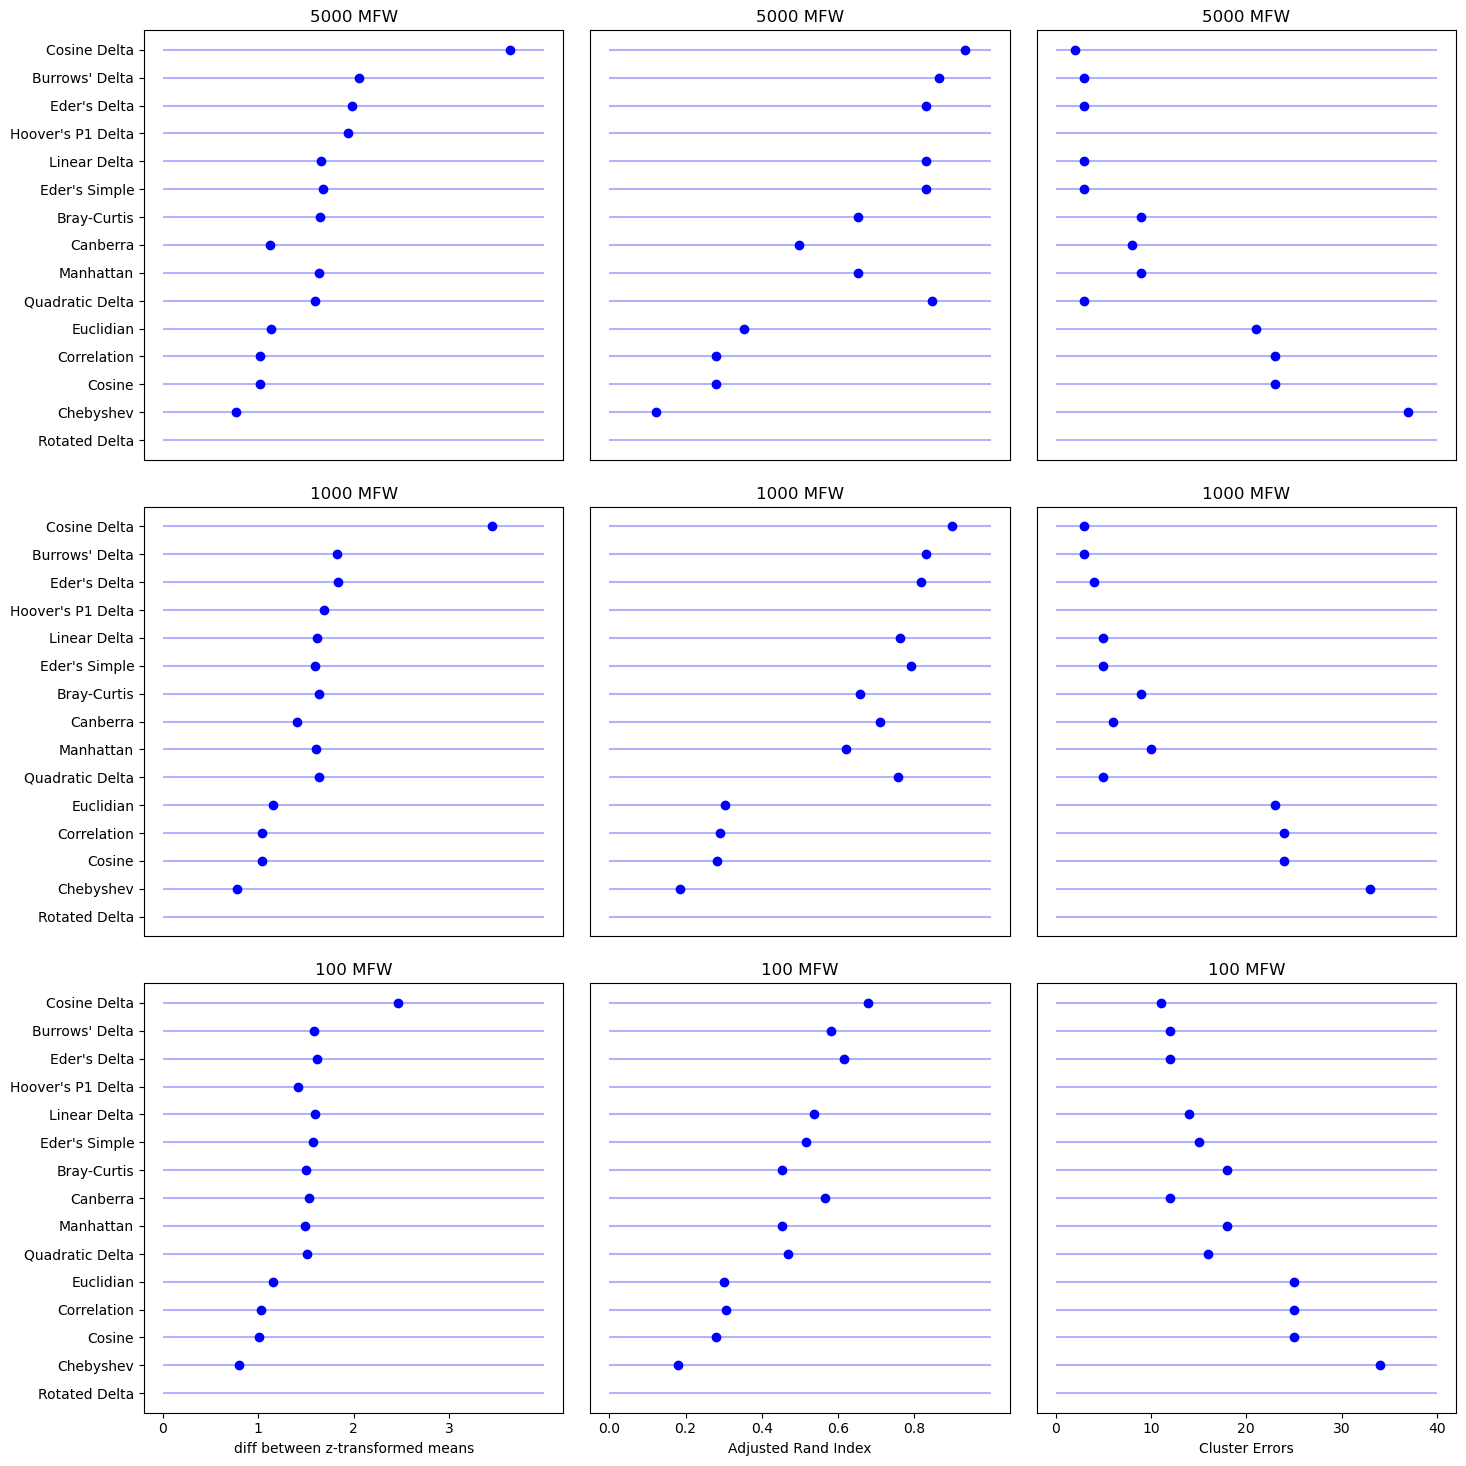

In [8]:
#max_performance, highrank = sort_eval_values_at_mff(eval_en)
highrank = refcor_highrank_en[::-1]
# only distances that are in the highrank list
eval_en["distance"] = eval_en["distance"].astype(str)
refcor_highrank_en = [str(x) for x in refcor_highrank_en]
eval_en = eval_en[eval_en["distance"].isin(refcor_highrank_en)]
eval_en["highrank"] = eval_en["distance"].apply(lambda x: highrank.index(x))

distances = eval_en["distance"].unique()

plot_results_of_eval(eval_en, len(distances)+1, title="EN lex. 1-gram", colour="blue")

KeyError: 'highrank'

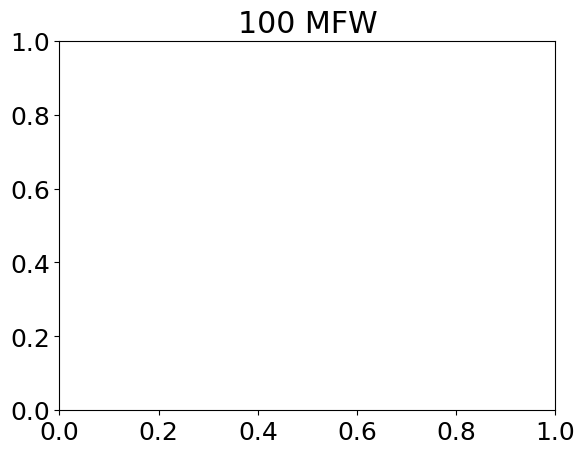

In [12]:
scatter_for_eval(eval_fr, 100, "simple_score", len(distances)+1, 4, yticks=True, xticks_list=[0, 1, 2, 3], colour="blue")

# Plot all four

In [37]:
refcor_highrank = [ 'Cosine Delta',
 "Burrows' Delta",
 "Eder's Delta",
 "Hoover's P1 Delta",
 'Linear Delta',
 "Eder's Simple",
 'Bray-Curtis',
 'Canberra',
 'Manhattan',
 'Quadratic Delta',
 'Euclidian',
 'Correlation',
 'Cosine',
 'Chebyshev',
 'Rotated Delta',
 'Entropy',
 'Min-Max']

highrank = refcor_highrank[::-1]

In [44]:
eval_en["distance"].nunique()

17

KeyError: 'highrank'

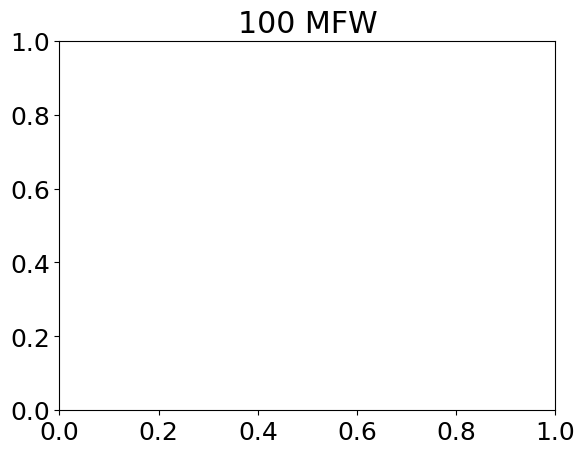

In [57]:
scatter_for_eval(eval_en, 100, "simple_score", len(distances)+1, 4, yticks=True, xticks_list=[0,1,2,3], colour="blue")

ValueError: x and y must be the same size

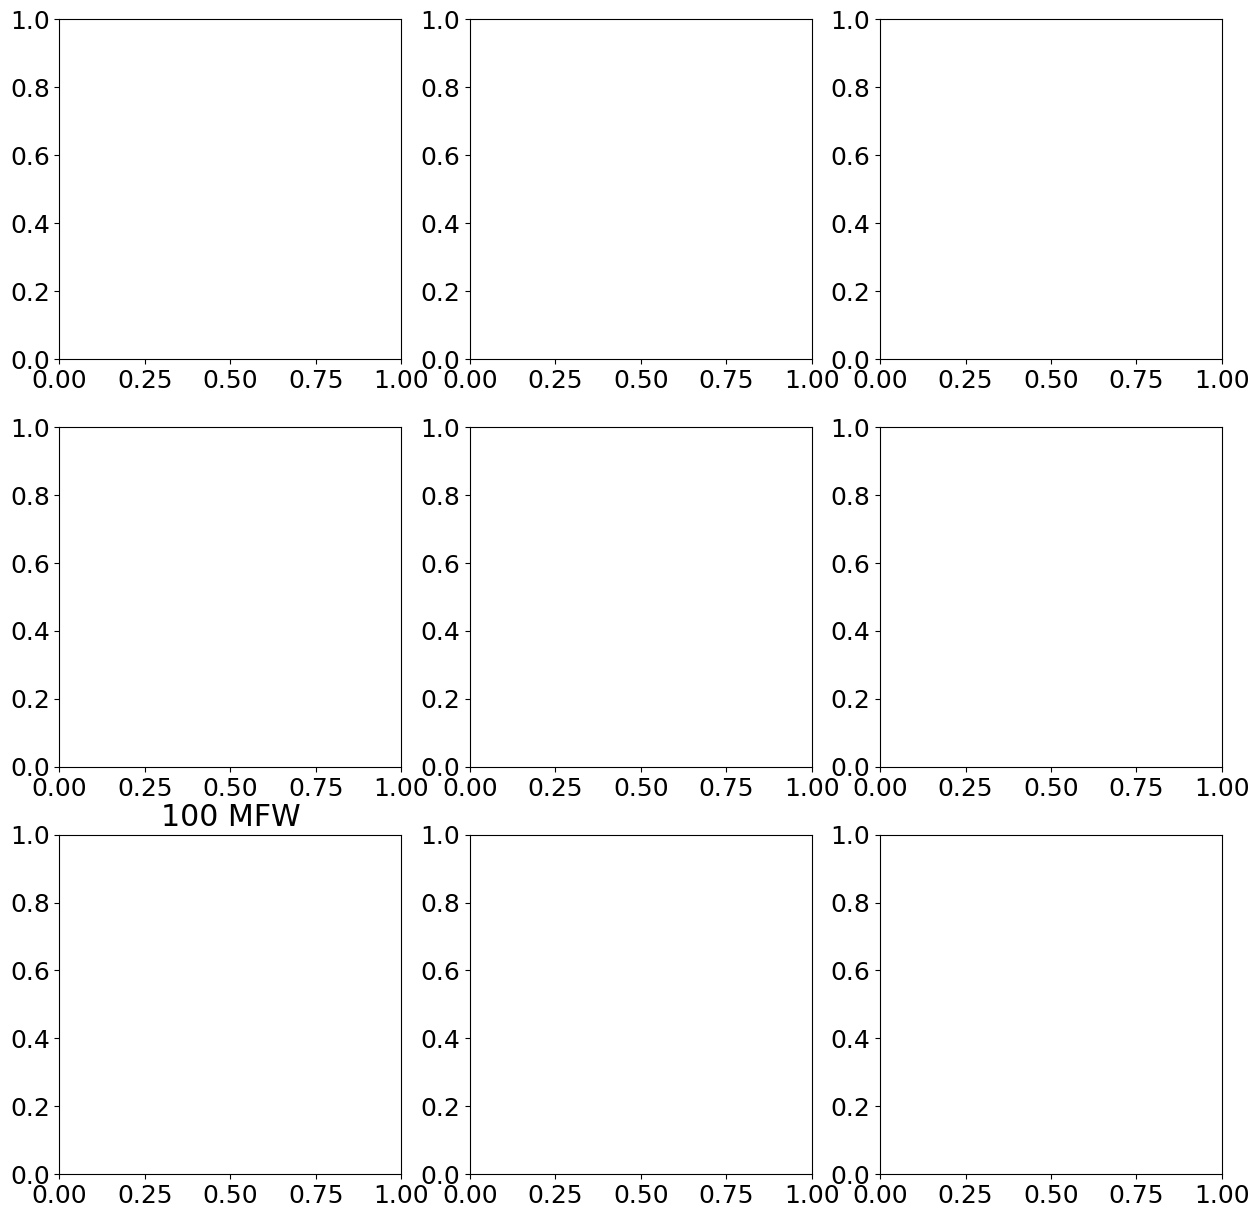

In [47]:

fig = plt.subplots(figsize=(15,15), nrows=3, ncols=3)

num_distances = len(distances)
col_en = "blue"
col_de = "red"
col_fr = "green"
col_ice = "orange"

# === SIMPLE SCORE ===
max_x = 4
x_list = [0, 1, 2, 3]

plt.subplot(3,3,7)
scatter_for_eval(eval_en, 100, "simple_score", num_distances, max_x, yticks=True, xticks_list=x_list, colour=col_en)
#scatter_for_eval(eval_de, 100, "simple_score", num_distances, max_x, yticks=True, xticks_list=x_list, colour=col_de)
#scatter_for_eval(eval_fr, 100, "simple_score", num_distances, max_x, yticks=True, xticks_list=x_list, colour=col_fr)
#scatter_for_eval(eval_ice, 100, "simple_score", num_distances, max_x, yticks=True, xticks_list=x_list, colour=col_ice)
plt.xlabel("diff between z-transformed means")

plt.subplot(3,3,4)
scatter_for_eval(eval_en, 1000, "simple_score", num_distances, max_x, yticks=True, colour=col_en)
scatter_for_eval(eval_de, 1000, "simple_score", num_distances, max_x, yticks=True, colour=col_de)
scatter_for_eval(eval_fr, 1000, "simple_score", num_distances, max_x, yticks=True, colour=col_fr)
scatter_for_eval(eval_ice, 1000, "simple_score", num_distances, max_x, yticks=True, colour=col_ice)

plt.subplot(3,3,1)
scatter_for_eval(eval_en, 5000, "simple_score", num_distances, max_x, yticks=True, colour=col_en)
scatter_for_eval(eval_de, 5000, "simple_score", num_distances, max_x, yticks=True, colour=col_de)
scatter_for_eval(eval_fr, 5000, "simple_score", num_distances, max_x, yticks=True, colour=col_fr)
scatter_for_eval(eval_ice, 5000, "simple_score", num_distances, max_x, yticks=True, colour=col_ice)

# === ARI ===
max_x = 1
x_list = [0, 0.2, 0.4, 0.6, 0.8]

plt.subplot(3,3,8)
scatter_for_eval(eval_en, 100, "ari", num_distances, max_x, xticks_list=x_list, colour=col_en)
scatter_for_eval(eval_de, 100, "ari", num_distances, max_x, xticks_list=x_list, colour=col_de)
scatter_for_eval(eval_fr, 100, "ari", num_distances, max_x, xticks_list=x_list, colour=col_fr)
scatter_for_eval(eval_ice, 100, "ari", num_distances, max_x, xticks_list=x_list, colour=col_ice)
plt.xlabel("Adjusted Rand Index")

plt.subplot(3,3,5)
scatter_for_eval(eval_en, 1000, "ari", num_distances, max_x, colour=col_en)
scatter_for_eval(eval_de, 1000, "ari", num_distances, max_x, colour=col_de)
scatter_for_eval(eval_fr, 1000, "ari", num_distances, max_x, colour=col_fr)
scatter_for_eval(eval_ice, 1000, "ari", num_distances, max_x, colour=col_ice)

plt.subplot(3,3,2)
scatter_for_eval(eval_en, 5000, "ari", num_distances, max_x, colour=col_en)
scatter_for_eval(eval_de, 5000, "ari", num_distances, max_x, colour=col_de)
scatter_for_eval(eval_fr, 5000, "ari", num_distances, max_x, colour=col_fr)
scatter_for_eval(eval_ice, 5000, "ari", num_distances, max_x, colour=col_ice)

# === CLUSTER ERRORS ===
max_x = 40
x_list = [0, 10, 20, 30, 40]

plt.subplot(3,3,9)
scatter_for_eval(eval_en, 100, "cl_error", num_distances, max_x, xticks_list=x_list, colour=col_en)
scatter_for_eval(eval_de, 100, "cl_error", num_distances, max_x, xticks_list=x_list, colour=col_de)
scatter_for_eval(eval_fr, 100, "cl_error", num_distances, max_x, xticks_list=x_list, colour=col_fr)
scatter_for_eval(eval_ice, 100, "cl_error", num_distances, max_x, xticks_list=x_list, colour=col_ice)
plt.xlabel("Cluster Errors")

plt.subplot(3,3,6)
scatter_for_eval(eval_en, 1000, "cl_error", num_distances, max_x, colour=col_en)
scatter_for_eval(eval_de, 1000, "cl_error", num_distances, max_x, colour=col_de)
scatter_for_eval(eval_fr, 1000, "cl_error", num_distances, max_x, colour=col_fr)
scatter_for_eval(eval_ice, 1000, "cl_error", num_distances, max_x, colour=col_ice)

plt.subplot(3,3,3)
scatter_for_eval(eval_en, 5000, "cl_error", num_distances, max_x, colour=col_en)
scatter_for_eval(eval_de, 5000, "cl_error", num_distances, max_x, colour=col_de)
scatter_for_eval(eval_fr, 5000, "cl_error", num_distances, max_x, colour=col_fr)
scatter_for_eval(eval_ice, 5000, "cl_error", num_distances, max_x, colour=col_ice)

# HARD-CODED LEGEND
plt.legend([
    plt.Line2D([], [], color=col_en, marker='o', linestyle='', label="EN"),
    plt.Line2D([], [], color=col_de, marker='o', linestyle='', label="DE"),
    plt.Line2D([], [], color=col_fr, marker='o', linestyle='', label="FR"),
    plt.Line2D([], [], color=col_ice, marker='o', linestyle='', label="ICE")
],
bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.show()